In [1]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import statistics
import matplotlib.ticker as mticker
from tqdm import tqdm


#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking/
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/Users/michelefilippucci/Data/ERA5/gr_tracking
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1990.nc
dictionaries


In [10]:
#IMPORT DATASET
ds = xr.load_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')
ds_comp = xr.load_dataset('../precipitation/ERA5_moisture_divergence_daily_northem_2.5x2.5_1940-2023.nc')
#store variables for the composite
DAV = ds['DAV_tracked']
zg = ds['zg']/9.8
anom = ds_comp['vimd']-ds_comp['vimd'].mean('time')
lat = ds['lat']
lon = ds['lon']
times = ds['time']

In [11]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in range(n_iter):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=(0))

#we subtract to the anom field the annual mean in order to have only deviations from the annual mean and remove the seasonal cycle
dates = []
for time in times:
    if str(time.values)[0:4] == '1940':
        dates.append(str(time.values)[5:10])
    else:
        break
usual_year = np.zeros((len(dates),37,144))
for i,date in tqdm(enumerate(dates)):
    for t,time in enumerate(times):
        if str(time.values)[5:10] == date:
            usual_year[i,:,:] += anom[t,:,:]
usual_year = usual_year/len(dates)
usual_year_repeat = np.repeat(usual_year, 84, axis = 0)
anom = anom - usual_year_repeat

In [14]:
#compute the composites
plon,plat = -35,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

series = DAV.loc[:,plat,plon]
list = []
list_an = []
list_east = [4, 7, 62, 90, 93, 178, 205, 244, 282, 284, 412, 582, 731, 847, 880, 935, 968, 975, 1017, 1020, 1102, 1153, 1156, 1477, 1584, 1586, 1587, 1622, 1654, 1695, 1698, 1701, 1785, 1830, 1870, 1924, 1927, 2073, 2125, 2165, 2346, 2348, 2437, 2439, 2478, 2481, 2526, 2652, 2654, 2658, 2702, 2741, 2749, 2791, 2881, 2912, 3029, 3033, 3160, 3161, 3207, 3347, 3351, 3432, 3439]
list_west = [27, 30, 60, 97, 176, 405, 457, 496, 583, 584, 623, 678, 725, 730, 771, 819, 821, 879, 933, 1021, 1047, 1052, 1053, 1196, 1198, 1200, 1245, 1248, 1249, 1423, 1655, 1657, 1660, 1928, 1972, 1975, 2023, 2522, 2604, 2661, 2841, 2883, 2989, 3162, 3293, 3431, 3521, 3588, 3589, 3590]
#list_east = [74, 259, 318, 326, 429, 519, 570, 582, 643, 843, 915, 1045, 1049, 1107, 1177, 1180, 1244, 1319, 1329, 1591, 1643, 1708, 1721, 1990, 2004, 2262, 2271, 2345, 2406, 2477, 2534, 2593, 2602, 2663, 2794, 2796, 2798, 2806, 2943, 2948, 2957, 3139, 3146, 3221, 3228, 3346, 3350, 3355, 3410, 3417, 3480, 3555, 3627, 3637, 3642, 3717, 3769, 3839, 3909, 3959, 3967, 4083, 4095, 4148, 4159, 4218, 4237, 4295, 4300, 4301, 4365, 4443, 4447, 4502, 4561, 4572, 4633, 4845, 4905, 5079, 5093, 5160, 5222, 5279, 5290, 5351, 5409, 5413]
#list_west = [262, 507, 647, 650, 654, 705, 721, 775, 846, 849, 1039, 1106, 1115, 1247, 1456, 1592, 1722, 1790, 1793, 1846, 2129, 2189, 2200, 2204, 2269, 2539, 2656, 2664, 2669, 2725, 2872, 2947, 3017, 3083, 3091, 3282, 3295, 3351, 3408, 3490, 3696, 3704, 3892, 3898, 4015, 4085, 4225, 4235, 4294, 4444, 4498, 4500, 4710, 4832, 4841, 4848, 4895, 5028, 5089, 5090, 5094, 5152, 5359, 5422, 5543]
for t,time in enumerate(times):
    if series[t] in list_east:#in list_west:
        list.append(zg.loc[time,:,:].values)
        list_an.append(anom.loc[time,:,:].values)
sum_t = sum(list)
sum_an = sum(list_an)
zg_comp = sum_t/len(list)
anom_comp = -np.mean(anom,axis=0) + sum_an/len(list_an)
t_st_anom = abs(anom_comp/Bootstrap(anom,len(list_an),1000)) > 2

/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:475: UserWarning: The .ylabels_left attribute is deprecated. Please use .left_labels to toggle visibility instead.
  warnings.warn('The .ylabels_left attribute is deprecated. Please '


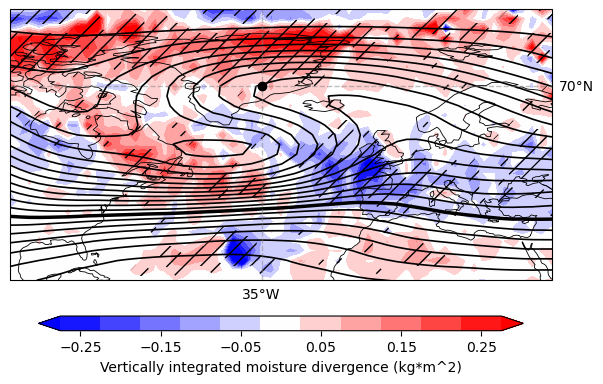

In [15]:
fig,ax = plt.subplots(nrows=1,ncols=1,figsize=(10,4),subplot_kw={'projection': ccrs.PlateCarree()})
title = ''
field = ma.masked_array(zg_comp,zg_comp==0)
extent =[-100,40,20,90] #Greenland
#extent =[-180,180,20,90] #Europe
ax.set_extent(extent, ccrs.PlateCarree())
ax.coastlines(linewidth = 0.6)
ax.plot(plon,plat,color='black', marker='o')
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
cont = ax.contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 1.2,
                    levels = np.arange(4600,7200,40)
                    )
cont2=ax.contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 2.5,
                    levels = [5600]
                    )
                    #cmap = "YlGnBu")
#c_range = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
c_range = np.arange(-0.275,0.28,0.05)
#ticks = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
ticks = np.arange(-0.25,0.28,0.1)
shadings = ax.contourf(lon,lat,anom_comp,
                      cmap='bwr',
                      extend = 'both', 
                      levels = c_range)
cs_p = ax.contourf(lon,lat,t_st_anom,levels = 1,colors='none',hatches=['','//'])
fig.colorbar(shadings,ticks=ticks,label='Vertically integrated moisture divergence (kg*m^2)',pad=0.1,orientation='horizontal',shrink=0.5,aspect=30)
ax.set_title(title)
plt.tight_layout()
plt.savefig('/Users/michelefilippucci/PLOTS/pres_exeter/winter_composite_greenland_vimd_east.png',dpi=300)
